# 3. Fast intrinsic clustering

For an ensemble of orthonormal frames, the intrinsic k-means problem is to choose a fixed number
of centres so that the sum of squared distances to the nearest centre is minimized.
Lloyd's method solves a sequence of Fréchet mean problems for this purpose, and it is the
repetition of these solves that we would like to avoid. We consider the alternative provided
by mini-batch updates. To allow a comparison both of the computing time and of the resulting
fits, we use the same synthetic observations, metric and stationarity tolerance for Lloyd's
method and for the Riemannian adaptation of e-means.

## Setup

Run from a checkout with `uv run --with jupyterlab --with matplotlib jupyter lab examples/`.
The setup selects the CPU before importing JAX and enables float64 before creating arrays.
For the figures we use serif text and Computer Modern mathematics; the colors are from
[Okabe and Ito's palette](https://jfly.uni-koeln.de/color/). Markers and line styles also distinguish the curves.

In [1]:
import os

# Select the CPU before JAX initializes a backend.
os.environ["CUDA_VISIBLE_DEVICES"] = ""
os.environ["JAX_PLATFORMS"] = "cpu"

import platform
from pathlib import Path
from time import perf_counter

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import linear_sum_assignment

import stiefel as sf

jax.config.update("jax_enable_x64", True)
style = Path("examples/stiefel.mplstyle") if Path("examples").is_dir() else Path("stiefel.mplstyle")
plt.style.use(style)
BLUE, VERMILION, GREEN, ORANGE, INK = plt.rcParams["axes.prop_cycle"].by_key()["color"]
print(f"Python {platform.python_version()}, JAX {jax.__version__}, stiefel {sf.__version__}")
print(jax.devices())
assert jax.default_backend() == "cpu"

Python 3.13.15, JAX 0.12.0.1, stiefel 0.1.0
[CpuDevice(id=0)]


## Generate a controlled problem

We construct four groups in $\mathrm{St}(12,2)$ and lift them into $\mathrm{St}(256,2)$.
Within each group, the tangent perturbations have zero sample mean and bounded length.
The group labels will be used only to assess the assignments, after fitting.
This is a small, separated example intended to make the computation inspectable.

In [2]:
rng = np.random.default_rng(2026)
n, rank, p = 256, 12, 2
n_clusters, per_cluster, radius = 4, 16, 0.18
alpha, tolerance = 0.0, 1e-6
base = np.linalg.qr(rng.standard_normal((rank, p)))[0]
groups = []
for _ in range(n_clusters):
    centre = sf.polar(base + 0.5 * rng.standard_normal((rank, p)))
    noise = jnp.asarray(rng.standard_normal((per_cluster, rank, p)))
    noise = jax.vmap(sf.project_tangent, in_axes=(None, 0))(centre, noise)
    noise -= noise.mean(axis=0)
    lengths = jax.vmap(lambda v, c=centre: sf.norm(c, v, alpha=alpha))(noise)
    noise *= radius / lengths.max()
    groups.append(jax.vmap(lambda v, c=centre: sf.exp(c, v, alpha=alpha))(noise))
small_frames = jnp.concatenate(groups)
basis = jnp.asarray(np.linalg.qr(rng.standard_normal((n, rank)))[0])
frames = sf.lift(basis, small_frames)
truth = np.repeat(np.arange(n_clusters), per_cluster)
frames.block_until_ready()
assert bool(jnp.all(jax.vmap(sf.is_frame)(frames)))
print("Ensemble:", frames.shape, "metric alpha:", alpha)

Ensemble: (64, 256, 2) metric alpha: 0.0


## Replace repeated mean solves with mini-batches

For a batch assigned to centre $C_j$, let $m_j$ be its size and let
$G_j=\sum_{i\in B_j}\operatorname{Log}_{C_j}(X_i)$.
The Riemannian e-means update is
$$N_j^+=(1-s_t)N_j+s_tm_j,\qquad
C_j^+=\operatorname{Exp}_{C_j}\left(\frac{s_t}{N_j^+}G_j\right).$$
Here $N_j$ is a decayed count and $s_t$ is the scheduled step.
The count normalization and schedule are adapted from
[Meta's e-means](https://arxiv.org/abs/2611.09501).
On a curved manifold, these quantities do not determine the exact mean of the weighted history.
Final intrinsic iterations are therefore used to refine the centres and check stationarity.

In [3]:
key = jax.random.key(0)
fit = sf.emeans(key, frames, n_clusters, alpha=alpha, tol=tolerance)
jax.block_until_ready(fit)
assert bool(fit.converged)
print(f"Converged: {bool(fit.converged)}, epochs: {int(fit.iterations)}")
print(f"Intrinsic inertia: {float(fit.inertia):.8f}")
print(f"Logarithms evaluated: {int(fit.log_evaluations)}")

Converged: True, epochs: 5
Intrinsic inertia: 1.35565812
Logarithms evaluated: 640


## Measure time and objective together

In order to quantify the computing time, let us now consider three values of the solver seed,
with the dataset held fixed throughout. Each call is repeated once after its result has become
available. The clock is read only after synchronization, since JAX otherwise allows Python to
proceed before a computation has finished. We retain both times. The first one includes whatever
compilation is still needed in the session, whereas the second one is used for the plot.
Because the earlier call to e-means has already compiled part of that solver, the first-call
times cannot be interpreted as independent cold starts. Each solver also uses its own
initialization, so that their comparison includes this difference.

In [4]:
rows = []
solutions = {}
for seed in range(3):
    for name, method in [("Lloyd", sf.kmeans), ("Riemannian e-means", sf.emeans)]:
        start = perf_counter()
        result = jax.block_until_ready(
            method(jax.random.key(seed), frames, n_clusters, alpha=alpha, tol=tolerance)
        )
        first_seconds = perf_counter() - start
        start = perf_counter()
        result = jax.block_until_ready(
            method(jax.random.key(seed), frames, n_clusters, alpha=alpha, tol=tolerance)
        )
        warm_seconds = perf_counter() - start
        assert bool(result.converged)
        rows.append((name, seed, first_seconds, warm_seconds, float(result.inertia)))
        solutions[(name, seed)] = result

print(f"{'Method':20s} {'Seed':>4s} {'First (s)':>10s} {'Repeat (s)':>11s} {'Inertia':>12s}")
for name, seed, first, warm, inertia in rows:
    print(f"{name:20s} {seed:4d} {first:10.3f} {warm:11.3f} {inertia:12.8f}")

Method               Seed  First (s)  Repeat (s)      Inertia
Lloyd                   0      3.019       0.290   1.35565812
Riemannian e-means      0      0.076       0.080   1.35565812
Lloyd                   1      0.237       0.241   1.35565812
Riemannian e-means      1      0.091       0.082   1.35565812
Lloyd                   2      0.258       0.282   1.35565812
Riemannian e-means      2      0.120       0.081   1.35565812


## Check the reported fits

For each fitted model, the distances from the observations to all centres are recomputed in
order to check the assignments. An assigned centre should attain the minimum distance for that
frame, and the sum of the squared assigned distances should equal the reported inertia.
The generating labels have been kept aside for this stage. Their agreement with the fitted
labels is computed after a permutation of the cluster names, since the names themselves have
no effect on the partition.

In [5]:
agreements = []
for result in solutions.values():
    distances = np.asarray(
        jax.vmap(lambda c: jax.vmap(lambda z: sf.distance(c, z, alpha=alpha))(frames))(result.centers)
    ).T
    assert np.isfinite(distances).all()
    labels = np.asarray(result.labels)
    assigned = distances[np.arange(len(frames)), labels]
    np.testing.assert_allclose(assigned, distances.min(axis=1), atol=1e-8)
    np.testing.assert_allclose(np.sum(assigned**2), result.inertia, rtol=1e-7, atol=1e-9)
    assert bool(jnp.all(jax.vmap(sf.is_frame)(result.centers)))
    counts = np.zeros((n_clusters, n_clusters), dtype=int)
    np.add.at(counts, (truth, labels), 1)
    row_ids, col_ids = linear_sum_assignment(-counts)
    agreements.append(counts[row_ids, col_ids].sum() / len(frames))
print(f"Agreement with generating groups: {min(agreements):.1%} to {max(agreements):.1%}")

Agreement with generating groups: 100.0% to 100.0%


## Compare the repeated calls

For each method, the results obtained with the three solver seeds are shown as individual
markers, while the median of the repeated-call times is indicated by a horizontal segment.
The inertia is the sum of squared canonical distances. These three runs describe variation
with the choice of seed on this dataset; they do not provide a confidence interval for
performance on other datasets.

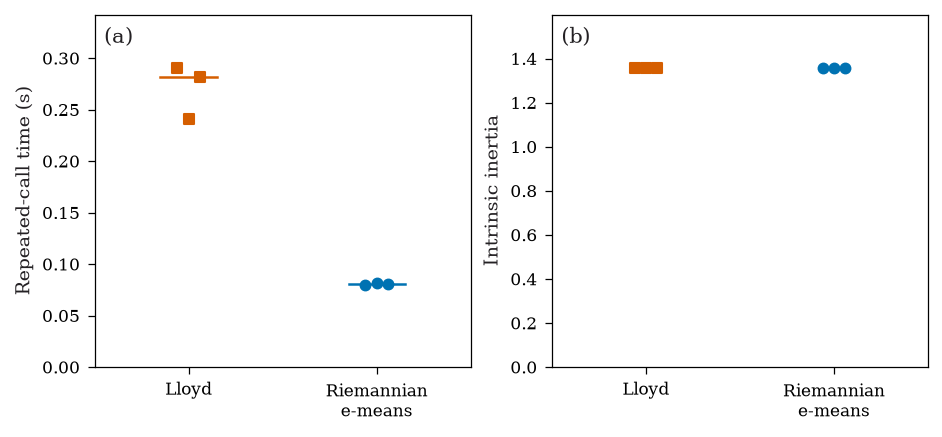

Ratio of median Lloyd to e-means time: 3.47
Range of intrinsic inertia: 1.35565812 to 1.35565812


In [6]:
names = ["Lloyd", "Riemannian e-means"]
fig, axes = plt.subplots(1, 2, figsize=(6.17, 2.8))
medians = []
for position, (name, color, marker) in enumerate(zip(names, [VERMILION, BLUE], ["s", "o"], strict=True)):
    selected = [row for row in rows if row[0] == name]
    seconds = np.array([row[3] for row in selected])
    inertia = np.array([row[4] for row in selected])
    offset = np.linspace(-0.06, 0.06, len(selected))
    axes[0].scatter(position + offset, seconds, c=color, marker=marker, s=22)
    axes[0].plot([position - 0.15, position + 0.15], [np.median(seconds)] * 2, color=color, lw=1.2)
    axes[1].scatter(position + offset, inertia, c=color, marker=marker, s=22)
    medians.append(np.median(seconds))
for ax, tag in zip(axes, ("a", "b"), strict=True):
    ax.set(xticks=[0, 1], xticklabels=["Lloyd", "Riemannian\ne-means"], xlim=(-0.5, 1.5), ylim=(0, None))
    ax.text(0.025, 0.965, f"({tag})", transform=ax.transAxes, va="top", fontsize=10)
axes[0].set_ylim(0, 1.18 * max(row[3] for row in rows))
axes[0].set_ylabel("Repeated-call time (s)")
axes[1].set_ylim(0, 1.18 * max(row[4] for row in rows))
axes[1].set_ylabel("Intrinsic inertia")
plt.show()
print(f"Ratio of median Lloyd to e-means time: {medians[0] / medians[1]:.2f}")
print(f"Range of intrinsic inertia: {min(r[4] for r in rows):.8f} to {max(r[4] for r in rows):.8f}")

All six runs converged to partitions that agree with the generating groups, and their
intrinsic inertia is 1.35565812 at the precision shown. The repeated calls to e-means
were faster in the saved run. Since initialization, assignment pruning and final
refinement also differ between the two solvers, the observed difference in time cannot
be attributed to the mini-batch update alone. It applies to this synthetic dataset on
the CPU, with the compilation already performed in this session.

When applying the method to other frames, check both `converged` and `inertia` before
using the centres. Further refinement can be obtained by increasing `polish_iter` or
`epochs` if the final check is unsuccessful. During the stochastic phase the loss may
increase, and a global optimum is not guaranteed by either method. For frames outside
the local domain of the logarithm, the iteration used to obtain a distance may itself fail.

## Further experiments

For each value of the radius, number of clusters or batch size, the comparison can be
repeated while keeping the observations fixed between solvers. The
[benchmark script](../benchmarks/clustering.py) allows a larger experiment to be run in
this way on the CPU, and its recorded cases are given in the [results](../benchmarks/results.md).
If the application depends only on column spans, it would also be appropriate to consider
a Grassmann formulation, since the orientation retained by a Stiefel frame would then be
irrelevant. Details of the assignment bounds and the research through November 2026 are
given in the [clustering note](../docs/fast-clustering.md).